In [ ]:

import multiprocessing

import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymc as pm
import pytensor.tensor as pt
import scipy.stats as stats
from scipy.optimize import curve_fit
from scipy.stats import norm
from pytensor.tensor import erf

In [ ]:
plt.rcParams.update({
    "font.family": "serif",
    "font.size": 15,
    "axes.labelsize": 15,
    "axes.titlesize": 15,
    "legend.fontsize": 15,
    "xtick.labelsize": 15,
    "ytick.labelsize": 15,
    "figure.figsize": (5.8, 3.6),  # tipico per colonna singola
    "lines.linewidth": 1.2,
    "axes.linewidth": 0.8,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,
})

In [ ]:
# ============================================================
# ENERGY RESOLUTION
# ============================================================
def sigma_fun(E):

    A = 3.68436e1
    B = 1.72714e4

    return (
        E * pt.sqrt(A/E + B/E**2)
        / 2.355
        / 100
    )
    


In [ ]:

def add_peak(ax, x, text, y_text, y_line_top=150):
    """
    ax       : axis
    x        : posizione del picco (keV)
    text     : label da scrivere
    y_text   : posizione testo
    y_line_top : altezza linea verticale
    """

    # linea verticale tratteggiata
    ax.vlines(
        x,
        0,
        y_line_top,
        ls='--',
        color='black',
        alpha=0.75
    )

    # annotazione (ruotata come nel tuo esempio)
    ax.annotate(
        text,
        xy=(x - 2, y_text),
        rotation=90,
        fontsize=11
    )

In [ ]:

# ============================================================
# DATA LOADING
# ============================================================
def load_spectrum(file_path, calibration, energy_range=(0, 3000)):
    """
    Load raw spectrum and convert channels to energy.
    """

    data = pd.read_csv(file_path, header=None)
    spectrum = data[0].to_numpy(dtype=np.float64)

    channels = np.arange(len(spectrum))

    E = (
        channels * calibration["a"]
        + calibration["b"]
        + calibration["c"] * channels**2
    )

    mask = (E >= energy_range[0]) & (E <= energy_range[1])

    return E[mask], spectrum[mask]

In [ ]:
# ============================================================
# HISTOGRAMMING
# ============================================================
def make_histogram(E, spectrum, bins):
    counts, edges = np.histogram(E, bins=bins, weights=spectrum)
    centers = 0.5 * (edges[1:] + edges[:-1])

    return centers, counts



In [ ]:

# ============================================================
# GAUSSIAN MODEL
# ============================================================
def gaussian_plus_bg(E, mu, sigma, area, background):
    """
    Gaussian normalized to total area + flat background.
    """

    gaussian = (
        area
        / (sigma * np.sqrt(2 * np.pi))
        * np.exp(-0.5 * ((E - mu) / sigma) ** 2)
    )

    return gaussian + background


In [ ]:
# ============================================================
# PEAK FITTING
# ============================================================
def fit_peak(E, counts, center, window=4, plot=True):
    """
    Fit a Gaussian peak + constant background.
    """

    mask = (E > center - window) & (E < center + window)

    E_roi = E[mask]
    counts_roi = counts[mask]

    sigma_guess = sigma_fun(center)

    p0 = [
        center,
        sigma_guess,
        np.sum(counts_roi),
        np.median(counts_roi),
    ]

    bounds = (
        [center - 1, 0.01, 0, 0],
        [center + 1, 10, np.inf, np.inf],
    )

    popt, pcov = curve_fit(
        gaussian_plus_bg,
        E_roi,
        counts_roi,
        p0=p0,
        bounds=bounds,
        #sigma=np.sqrt(counts_roi),
        maxfev=10000,
    )

    perr = np.sqrt(np.diag(pcov))

    result = {
        "mu": popt[0],
        "sigma": popt[1],
        "N": popt[2],
        "B": popt[3],
        "err_mu": perr[0],
        "err_sigma": perr[1],
        "err_N": perr[2],
        "err_B": perr[3],
    }

    if plot:
        fig, ax = plt.subplots(
            2,
            1,
            figsize=(7, 6),
            sharex=True,
            gridspec_kw={"height_ratios": [3, 1]},
        )

        E_fit = np.linspace(E_roi.min(), E_roi.max(), 400)
        model_fit = gaussian_plus_bg(E_fit, *popt)

        ax[0].step(E_roi, counts_roi, where="mid", color="black", label="Data")
        ax[0].plot(E_fit, model_fit, color="red", lw=2, label="Fit")

        ax[0].set_ylabel(f"Counts / {E_roi[1]-E_roi[0]:.2f} keV")
        ax[0].set_title(f"Peak @ {center:.2f} keV")
        ax[0].legend()
        ax[0].grid(alpha=0.3)

        residuals = counts_roi - gaussian_plus_bg(E_roi, *popt)

        ax[1].scatter(E_roi, residuals, s=15)
        ax[1].axhline(0, color="red")
        ax[1].set_xlabel("Energy [keV]")
        ax[1].set_ylabel("Residuals")
        ax[1].grid(alpha=0.3)

        plt.tight_layout()
        plt.show()

    return result


In [ ]:

# ============================================================
# BUILD TOTAL DATASET
# ============================================================
def build_total_spectrum(files_config, bins):
    all_histograms = []
    total_time = 0

    for key, cfg in files_config.items():
        E, spectrum = load_spectrum(
            cfg["path"],
            cfg["calibration"],
            ENERGY_RANGE,
        )

        E_centers, counts = make_histogram(E, spectrum, bins)

        all_histograms.append(counts)
        total_time += cfg["time"]

    total_counts = np.sum(all_histograms, axis=0)

    return E_centers, total_counts, total_time

# inizio

In [ ]:

FILES = {
    "50d": {
        "path": "csv-files/zro2_white&green_ 50_days.csv",
        "time": 4279386,
        "calibration": {
            "a": 0.357304,
            "b": -0.295444,
            "c": 1.352297e-9,
        },
    },
    "90d": {
        "path": "csv-files/90_days.csv",
        "time": 7550023,
        "calibration": {
            "a": 4.179423e-01,
            "b": 1.2696e-01,
            "c": 1.514025e-08,
        },
    },
}

In [ ]:
ENERGY_RANGE = (0, 3000)
BIN_WIDTH = 0.42


SIGNAL = {
    "mu": 369.9,
    "roi": (345, 415),
}

SAMPLING_CONFIG = {
    "draws": 2000,
    "tune": 2000,
    "chains": 4,
    "target_accept": 0.95,
}


In [ ]:
# ============================================================
# MAIN DATA PREPARATION
# ============================================================
BINS = np.arange(
    ENERGY_RANGE[0],
    ENERGY_RANGE[1] + BIN_WIDTH,
    BIN_WIDTH
)

E_tot, Ntot, t_tot = build_total_spectrum(FILES, BINS)

print(
    f"Total counts = {np.sum(Ntot):.0f} "
    f"in {t_tot / (60 * 60 * 24):.1f} days"
)


Total counts = 42047 in 136.9 days


In [ ]:
peaks = [409.46,
         445.03,
         404.85,
         427.096,
         401.81,
         351.9,
         351.0592]
peaks_lines = [354.1,
               #385.1,
               391.3,
               409.8,
               416.9,
               438.9,
               445.2,
               452.2]

peaks_strange = [ 369, 379, 386, 393, 421, 433]


Text(0.5, 0, 'E (keV)')

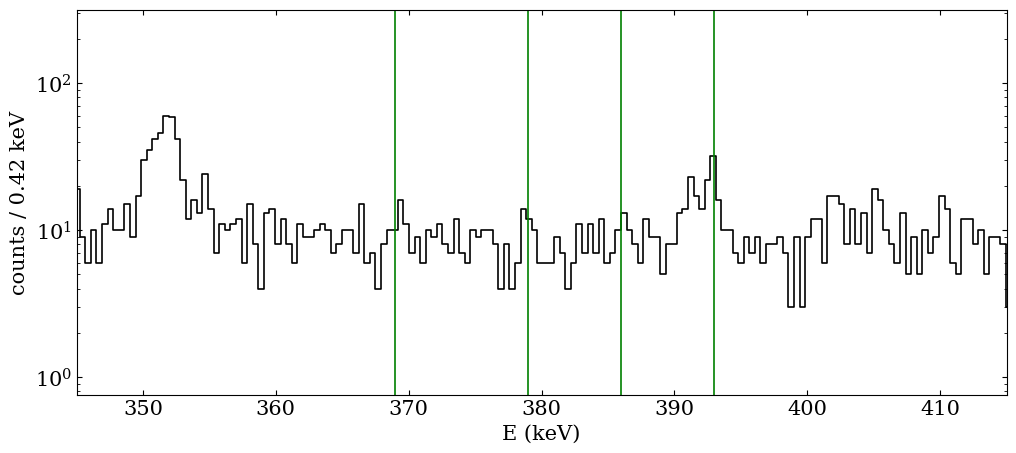

In [ ]:
plt.figure(figsize=(12,5))
plt.step(E_tot, Ntot, where="mid", color="black")
#plt.axvline(SIGNAL["mu"], color = 'green', ls = '--')
'''
for p in peaks:
    plt.axvline(p,  color = 'red')
for p in peaks_lines:
    plt.axvline(p, color = 'blue')
'''
for p in peaks_strange:
    plt.axvline(p, color = 'green')
plt.yscale('log')
plt.xlim(SIGNAL["roi"][0], SIGNAL["roi"][1])
plt.ylabel("counts / 0.42 keV")
plt.xlabel("E (keV)")

In [ ]:
FILES['50d']['path']

'csv-files/zro2_white&green_ 50_days.csv'

In [ ]:
BACKGROUND_PEAKS = {
    "²¹¹Bi":{"E": 351.05, "N":0},
    "²¹⁴Pb": {"E": 351.92, "N": 0},
    "": {"E": 354.1, "N": 18},
    "70Ge(n,γ)": {"E": 391.3, "N" :0},
    "115In(n,γ)": {"E":385.1 , "N":0},
    "219Rn": {"E": 401.8, "N": 18},
    "²¹¹Pb": {"E": 404.85, "N": 18},
    "²²⁸Ac ": {"E": 409.462, "N": 3.55},
    #"²¹¹Pb_2": {"E": 427.09, "N": 18},
    #"⁴⁰K (DEP)" :{"E":438.9, "N":0},
    "p1" : {"E": 369, "N":0},
    "p2" : {"E": 379, "N":0},
    "p3" : {"E": 386, "N":0},
    "p4" : {"E": 393, "N":0},
    #"p5" : {"E": 421, "N":0},
    #"p6" : {"E": 433, "N":0}
}

In [ ]:
roi_mask = (
    (E_tot > SIGNAL["roi"][0]) &
    (E_tot < SIGNAL["roi"][1])
)

E_roi = E_tot[roi_mask]
counts_roi = Ntot[roi_mask]

In [ ]:
bin_edges = BINS
bin_centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])

# ============================================================
# ROI
# ============================================================
roi_mask = (
    (bin_centers >= SIGNAL["roi"][0]) &
    (bin_centers <= SIGNAL["roi"][1])
)

# Conteggi nella ROI
counts_roi = Ntot[roi_mask]

# Centri dei bin nella ROI
E_roi = bin_centers[roi_mask]

# Edge dei bin nella ROI
idx = np.where(roi_mask)[0]
bin_edges_roi = bin_edges[idx[0]:idx[-1] + 2]

# Larghezza dei bin (costante)
bin_width = bin_edges_roi[1] - bin_edges_roi[0]


In [ ]:
import numpy as np
import pymc as pm
import pytensor.tensor as pt
import multiprocessing


# ============================================================
# BINNING / ROI
# ============================================================

edges_low = np.asarray(bin_edges_roi[:-1], dtype=float)
edges_high = np.asarray(bin_edges_roi[1:], dtype=float)

E_min = edges_low[0]
E_max = edges_high[-1]

ROI_width = E_max - E_min
bin_width = edges_high - edges_low

# Centro della ROI
E_center = 0.5 * (E_min + E_max)

# Numero totale di conteggi nella ROI
N_tot = np.sum(counts_roi)


# ============================================================
# GAUSSIAN CDF
# ============================================================

def gaussian_cdf(x, mu, sigma):
    return 0.5 * (
        1.0
        + pt.erf(
            (x - mu) /
            (sigma * pt.sqrt(2.0))
        )
    )


# ============================================================
# INTEGRALE GAUSSIANO SU OGNI BIN
# ============================================================

def bin_integral(mu, sigma, low, high):

    return (
        gaussian_cdf(high, mu, sigma)
        - gaussian_cdf(low, mu, sigma)
    )


# ============================================================
# MODELLO
# ============================================================

with pm.Model() as model:

    # ========================================================
    # PICCHI DI BACKGROUND
    # ========================================================

    A_bg = []
    mu_bg = []

    for name in BACKGROUND_PEAKS:

        fit = BACKGROUND_PEAKS[name]

        # Ampiezza totale del picco
        #A = pm.HalfNormal(
        A = pm.HalfFlat(    
            f"A_{name}",
            #sigma=N_tot
        )

        # Posizione del picco
        mu = pm.Normal(
            f"mu_{name}",
            mu=fit["E"],
            sigma=0.5
        )

        A_bg.append(A)
        mu_bg.append(mu)

    A_bg = pt.stack(A_bg)
    mu_bg = pt.stack(mu_bg)


    # ========================================================
    # SEGNALE
    # ========================================================

    #A = pm.HalfNormal(
     A_signal = pm.HalfFlat(
        "A_signal",
       # sigma=N_tot
    )

    mu_signal = pm.Normal(
        "mu_signal",
        mu=SIGNAL["mu"],
        sigma=0.5
    )

    # Risoluzione energetica del segnale
    sigma_signal = sigma_fun(mu_signal)


    # ========================================================
    # SIGMA DEI PICCHI DI BACKGROUND
    # ========================================================

    sigma_bg_list = []

    for i, name in enumerate(BACKGROUND_PEAKS):

        # Picco composito con sigma libera
        if name == "²²⁸Ac+²⁰⁸Tl+ann":

            sigma_i = pm.HalfNormal(
                f"sigma_{name}",
                sigma=2.0
            )

        else:

            # Sigma determinata dalla funzione
            # di risoluzione energetica
            sigma_i = sigma_fun(mu_bg[i])

        sigma_bg_list.append(sigma_i)

    sigma_bg = pt.stack(sigma_bg_list)


    # ========================================================
    # CONTINUUM BACKGROUND
    #
    # Modello:
    #
    # f(E) ∝ exp(a*x + b*x²)
    #
    # con
    #
    # x = (E - E_center) / ROI_width
    #
    # a = pendenza
    # b = curvatura
    #
    # Se b = 0:
    #
    # f(E) ∝ exp(a*x)
    #
    # cioè semplice esponenziale.
    # ========================================================

    # --------------------------------------------------------
    # Numero totale di eventi del continuum
    # --------------------------------------------------------

    N_exp = pm.HalfNormal(
        "N_exp",
        sigma=N_tot
    )


    # --------------------------------------------------------
    # Pendenza
    # --------------------------------------------------------

    a_exp = pm.Normal(
        "a_exp",
        mu=0.0,
        sigma=3.0
    )


    # --------------------------------------------------------
    # Curvatura
    #
    # Prior centrato su zero:
    #
    # b = 0 --> esponenziale semplice
    #
    # Manteniamo sigma relativamente piccola per evitare
    # che il continuum diventi troppo flessibile.
    # --------------------------------------------------------

    b_exp = pm.Normal(
        "b_exp",
        mu=0.0,
        sigma=0.5
    )


    # ========================================================
    # VARIABILE ENERGETICA NORMALIZZATA
    # ========================================================

    x_low = (
        edges_low - E_center
    ) / ROI_width

    x_high = (
        edges_high - E_center
    ) / ROI_width

    x_mid = 0.5 * (
        x_low + x_high
    )

    dx = (
        x_high - x_low
    )


    # ========================================================
    # CONTINUUM NEI BIN
    #
    # Usiamo il valore al centro del bin:
    #
    # integral ≈ f(x_mid) * dx
    #
    # È molto veloce computazionalmente.
    # ========================================================

    log_f_mid = (
        a_exp * x_mid
        +
        b_exp * x_mid**2
    )


    # Protezione numerica
    log_f_mid = pt.clip(
        log_f_mid,
        -50.0,
        50.0
    )


    f_mid = pt.exp(
        log_f_mid
    )


    # Integrale approssimato del continuum
    unnormalized_bin = (
        f_mid * dx
    )


    # ========================================================
    # NORMALIZZAZIONE
    #
    # La somma delle probabilità sui bin deve essere 1.
    # ========================================================

    normalization = pt.sum(
        unnormalized_bin
    )

    exp_bin_probability = (
        unnormalized_bin
        /
        normalization
    )


    # ========================================================
    # NUMERO ATTESO DI EVENTI DEL CONTINUUM
    # ========================================================

    exp_bg_bins = (
        N_exp
        *
        exp_bin_probability
    )


    # ========================================================
    # SEGNALE GAUSSIANO
    # ========================================================

    sig = bin_integral(
        mu_signal,
        sigma_signal,
        edges_low,
        edges_high
    )


    # ========================================================
    # PICCHI DI BACKGROUND
    # ========================================================

    bg = pt.stack([

        bin_integral(
            mu_bg[i],
            sigma_bg[i],
            edges_low,
            edges_high
        )

        for i in range(
            len(BACKGROUND_PEAKS)
        )
    ])


    # ========================================================
    # MODELLO TOTALE
    # ========================================================

    lambda_E = (

        # Continuum
        exp_bg_bins

        +

        # Segnale
        A_signal * sig

        +

        # Picchi background
        pt.sum(
            A_bg[:, None] * bg,
            axis=0
        )
    )


    # ========================================================
    # PROTEZIONE NUMERICA
    # ========================================================

    lambda_E = pt.clip(
        lambda_E,
        1e-9,
        np.inf
    )


    # ========================================================
    # LIKELIHOOD
    # ========================================================

    obs = pm.Poisson(
        "obs",
        mu=lambda_E,
        observed=counts_roi
    )


# ============================================================
# SAMPLING
# ============================================================

with model:

    trace = pm.sample(

        draws=2000,

        tune=4000,

        chains=4,

        cores=min(
            4,
            multiprocessing.cpu_count()
        ),

        target_accept=0.95,

        init="jitter+adapt_diag",

        return_inferencedata=True,

        progressbar=False
    )

Initializing NUTS using jitter+adapt_diag...
/home/ritaferi/pymc-env/lib/python3.12/site-packages/pytensor/link/c/cmodule.py:2986: UserWarning: PyTensor could not link to a BLAS installation. Operations that might benefit from BLAS will be severely degraded.
This usually happens when PyTensor is installed via pip. We recommend it be installed via conda/mamba/pixi instead.
Alternatively, you can use an experimental backend such as Numba or JAX that perform their own BLAS optimizations, by setting `pytensor.config.mode == 'NUMBA'` or passing `mode='NUMBA'` when compiling a PyTensor function.
For more options and details see https://pytensor.readthedocs.io/en/latest/troubleshooting.html#how-do-i-configure-test-my-blas-library
  warnings.warn(
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [A_²¹¹Bi, mu_²¹¹Bi, A_²¹⁴Pb, mu_²¹⁴Pb, A_, mu_, A_70Ge(n,γ), mu_70Ge(n,γ), A_115In(n,γ), mu_115In(n,γ), A_219Rn, mu_219Rn, A_²¹¹Pb, mu_²¹¹Pb, A_²²⁸Ac , mu_²²⁸Ac , A_p1, mu_p1, A_p2, mu_p2, A_p3, mu_p3,

In [ ]:
summary = az.summary(trace, round_to=4)
summary

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
mu_²¹¹Bi,350.7440,0.3437,350.0976,351.3149,0.0228,0.0348,498.5817,144.6279,1.0057
mu_²¹⁴Pb,351.8858,0.2145,351.6398,352.2012,0.0162,0.0360,626.8974,157.5619,1.0072
mu_,354.4490,0.2788,353.9357,354.9713,0.0032,0.0043,7745.8218,4977.4252,1.0006
"mu_70Ge(n,γ)",391.2601,0.3027,390.6961,391.8336,0.0042,0.0043,5502.0116,3995.3392,1.0007
"mu_115In(n,γ)",385.0679,0.5482,384.0828,386.1173,0.0064,0.0054,7370.7131,6613.8908,1.0000
mu_219Rn,402.0288,0.2483,401.5624,402.5007,0.0026,0.0027,9370.2933,5808.6709,1.0002
mu_²¹¹Pb,405.0771,0.2585,404.5783,405.5570,0.0028,0.0034,8874.5513,6013.8589,1.0005
mu_²²⁸Ac,409.9025,0.3579,409.2007,410.5406,0.0046,0.0055,6920.0374,3671.7628,1.0001
mu_p1,369.1337,0.4085,368.3275,369.8797,0.0050,0.0055,6962.2671,5343.3991,0.9998
mu_p2,379.0072,0.3723,378.2748,379.6839,0.0043,0.0048,7704.0213,5570.9696,1.0001


Variabili A incluse nel correlation plot:
A_²¹¹Bi
A_²¹⁴Pb
A_
A_70Ge(n,γ)
A_115In(n,γ)
A_219Rn
A_²¹¹Pb
A_²²⁸Ac 
A_p1
A_p2
A_p3
A_p4
A_signal


/home/ritaferi/pymc-env/lib/python3.12/site-packages/arviz/plots/backends/matplotlib/pairplot.py:223: UserWarning: rcParams['plot.max_subplots'] (40) is smaller than the number of resulting pair plots with these variables, generating only a 8x8 grid
  warnings.warn(


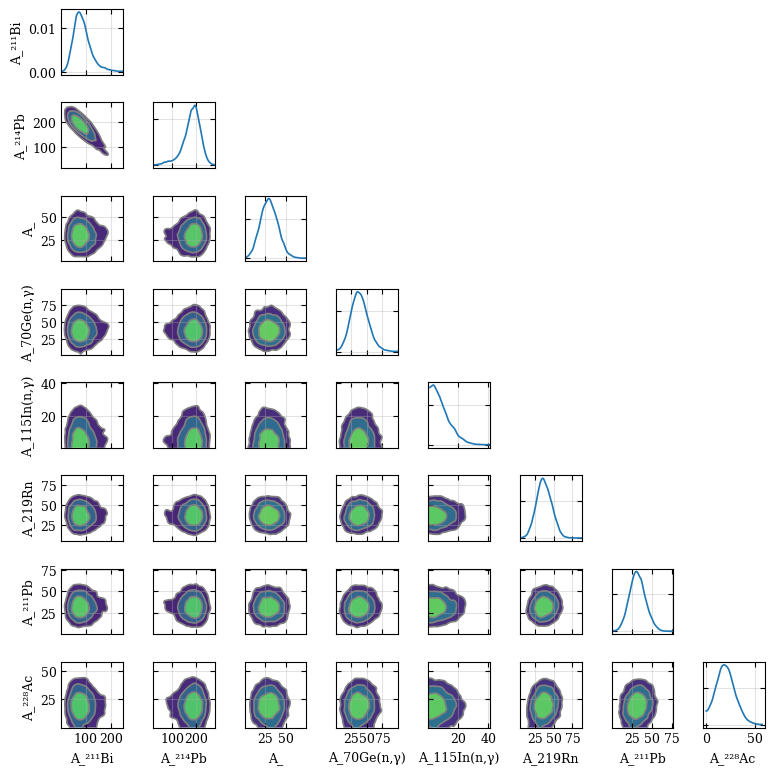

In [ ]:
# ============================================================
# CORRELATION PLOTS — TOTAL COUNTS / AREAS
# ============================================================

A_vars = [
    v
    for v in trace.posterior.data_vars
    if v.startswith("A_")
]

print("Variabili A incluse nel correlation plot:")
for v in A_vars:
    print(v)


axes = az.plot_pair(
    trace,
    var_names=A_vars,
    kind="kde",
    marginals=True,
    figsize=(8, 8),
    textsize=9,
)

for ax in np.asarray(axes).flatten():
    ax.grid(alpha=0.35)

plt.tight_layout()
plt.show()

In [ ]:


# ============================================================
# POSTERIOR OF SIGNAL
# ============================================================
signal_samples = trace.posterior["A_signal"].values.flatten()

N_signal_90 = np.percentile(signal_samples, 90)
N_signal_95 = np.percentile(signal_samples, 95)

print()
print("=" * 60)
print(f"90% upper limit on signal counts : {N_signal_90:.3f}")
print(f"95% upper limit on signal counts : {N_signal_95:.3f}")
print("=" * 60)


90% upper limit on signal counts : 19.181
95% upper limit on signal counts : 22.789


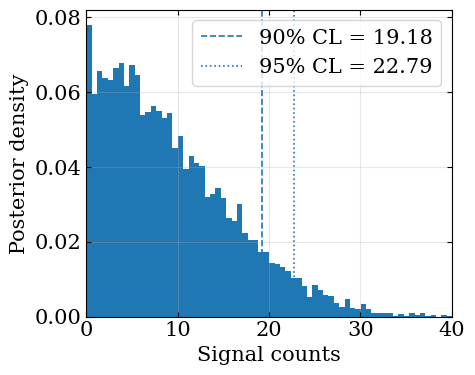

In [ ]:
# ============================================================
# SIGNAL POSTERIOR PLOT
# ============================================================
plt.figure(figsize=(5,4))

plt.hist(signal_samples, bins=75, density=True)

plt.axvline(
    N_signal_90,
    linestyle="--",
    label=f"90% CL = {N_signal_90:.2f}",
)

plt.axvline(
    N_signal_95,
    linestyle=":",
    label=f"95% CL = {N_signal_95:.2f}",
)

plt.xlabel("Signal counts")
plt.ylabel("Posterior density")
plt.grid(alpha=0.3)
plt.legend()
plt.xlim(0,40)
plt.tight_layout()
plt.show()



In [ ]:
# ============================================================
# POSTERIOR EXTRACTION
# ============================================================

background_names = list(BACKGROUND_PEAKS.keys())

idata = trace
posterior = idata.posterior


# ============================================================
# QUADRATIC EXPONENTIAL BACKGROUND
# ============================================================

# Total number of exponential-background events
# inside the ROI

N_exp_s = (
    posterior["N_exp"]
    .values
    .reshape(-1)
)

# Linear coefficient of the exponential background

a_exp_s = (
    posterior["a_exp"]
    .values
    .reshape(-1)
)

# Quadratic coefficient of the exponential background

b_exp_s = (
    posterior["b_exp"]
    .values
    .reshape(-1)
)


# ============================================================
# SIGNAL
# ============================================================

A_signal_s = (
    posterior["A_signal"]
    .values
    .reshape(-1)
)

mu_signal_s = (
    posterior["mu_signal"]
    .values
    .reshape(-1)
)


# ============================================================
# BACKGROUND PEAKS
# ============================================================

A_bg_s = {
    name: posterior[f"A_{name}"]
    .values
    .reshape(-1)
    for name in background_names
}

mu_bg_s = {
    name: posterior[f"mu_{name}"]
    .values
    .reshape(-1)
    for name in background_names
}

In [ ]:
import scipy

In [ ]:
SPECIAL_PEAK = "²²⁸Ac+²⁰⁸Tl+ann"

if f"sigma_{SPECIAL_PEAK}" in posterior.data_vars:

    sigma_special_s = (
        posterior[f"sigma_{SPECIAL_PEAK}"]
        .values
        .reshape(-1)
    )

    has_special_sigma = True

else:

    sigma_special_s = None
    has_special_sigma = False


In [ ]:


def sigma_fun_np(E):

    A = 3.68436e1
    B = 1.72714e4

    return (
        E * np.sqrt(A / E + B / E**2)
        / 2.355
        / 100
    )


# ============================================================
# 2. POSTERIOR
# ============================================================

posterior = trace.posterior

n_posterior_samples = (
    posterior.sizes["chain"]
    * posterior.sizes["draw"]
)

print("Numero di posterior samples:", n_posterior_samples)


# ============================================================
# 3. ESTRAZIONE DEI PARAMETRI
# ============================================================

A_signal_s = (
    posterior["A_signal"]
    .values
    .reshape(-1)
)

mu_signal_s = (
    posterior["mu_signal"]
    .values
    .reshape(-1)
)


# ------------------------------------------------------------
# Continuum quadratico
# ------------------------------------------------------------

N_exp_s = (
    posterior["N_exp"]
    .values
    .reshape(-1)
)

a_exp_s = (
    posterior["a_exp"]
    .values
    .reshape(-1)
)

b_exp_s = (
    posterior["b_exp"]
    .values
    .reshape(-1)
)


# ------------------------------------------------------------
# Background peaks
# ------------------------------------------------------------

background_names = list(BACKGROUND_PEAKS.keys())

A_bg_s = {
    name: posterior[f"A_{name}"]
    .values
    .reshape(-1)
    for name in background_names
}

mu_bg_s = {
    name: posterior[f"mu_{name}"]
    .values
    .reshape(-1)
    for name in background_names
}


# ============================================================
# 5. ROI
# ============================================================

E_min = edges_low[0]
E_max = edges_high[-1]

ROI_width = E_max - E_min

E_center = 0.5 * (E_min + E_max)


# ============================================================
# 6. CENTRI DEI BIN
# ============================================================

E_mid = 0.5 * (
    edges_low + edges_high
)

bin_width_array = (
    edges_high - edges_low
)

# Se i bin sono uniformi possiamo usare bin_width.
# Per sicurezza usiamo direttamente il vettore.
dx = bin_width_array


# ============================================================
# 7. QUADRATIC EXPONENTIAL
# ============================================================
#
# f(E) ~ exp(a*x + b*x^2)
#
# x = (E - E_center) / ROI_width
#

x_mid = (
    E_mid - E_center
) / ROI_width


# ============================================================
# 8. ARRAY PER SALVARE I RISULTATI
# ============================================================

lambda_total_samples = []

lambda_bkg_samples = []

signal_curves = []

background_curves = []

total_curves = []


# ============================================================
# 9. NUMERO DI CURVE DA PLOTTARE
# ============================================================

# IMPORTANTE:
# non usare questo numero per calcolare media e percentili.
# Le statistiche saranno calcolate su TUTTI i posterior samples.

n_curves = min(
    100,
    n_posterior_samples
)

plot_indices = np.linspace(
    0,
    n_posterior_samples - 1,
    n_curves,
    dtype=int
)
n_posterior_samples = 100

# ============================================================
# 10. LOOP SU TUTTI I POSTERIOR SAMPLES
# ============================================================

for i in range(n_posterior_samples):

    # ========================================================
    # SIGNAL
    # ========================================================

    A_sig = A_signal_s[i]

    mu_sig = mu_signal_s[i]

    # sigma NUMPY
    sigma_sig = sigma_fun_np(mu_sig)

    # --------------------------------------------------------
    # Gaussian bin integral
    # --------------------------------------------------------

    z_high = (
        edges_high - mu_sig
    ) / (
        np.sqrt(2.0) * sigma_sig
    )

    z_low = (
        edges_low - mu_sig
    ) / (
        np.sqrt(2.0) * sigma_sig
    )

    signal_i = (
        A_sig
        * 0.5
        * (
            scipy.special.erf(z_high)
            - scipy.special.erf(z_low)
        )
    )


    # ========================================================
    # BACKGROUND PEAKS
    # ========================================================

    bg_i = np.zeros_like(
        E_mid,
        dtype=float
    )

    for name in background_names:

        # ----------------------------------------------------
        # Amplitude
        # ----------------------------------------------------

        A_bg = A_bg_s[name][i]

        # ----------------------------------------------------
        # Peak position
        # ----------------------------------------------------

        mu_bg = mu_bg_s[name][i]


        # ----------------------------------------------------
        # Sigma
        # ----------------------------------------------------

        if (
            name == SPECIAL_PEAK
            and has_special_sigma
        ):

            sigma_bg = sigma_special_s[i]

        else:

            # =================================================
            # QUI USIAMO SOLO NUMPY
            # NIENTE .eval()
            # =================================================

            sigma_bg = sigma_fun_np(mu_bg)


        # ----------------------------------------------------
        # Gaussian bin integral
        # ----------------------------------------------------

        z_high = (
            edges_high - mu_bg
        ) / (
            np.sqrt(2.0) * sigma_bg
        )

        z_low = (
            edges_low - mu_bg
        ) / (
            np.sqrt(2.0) * sigma_bg
        )

        peak_i = (
            A_bg
            * 0.5
            * (
                scipy.special.erf(z_high)
                - scipy.special.erf(z_low)
            )
        )

        bg_i += peak_i


    # ========================================================
    # QUADRATIC EXPONENTIAL CONTINUUM
    # ========================================================

    N_exp_i = N_exp_s[i]

    a_exp_i = a_exp_s[i]

    b_exp_i = b_exp_s[i]


    # --------------------------------------------------------
    # log f(E)
    # --------------------------------------------------------

    log_f_mid = (
        a_exp_i * x_mid
        + b_exp_i * x_mid**2
    )


    # --------------------------------------------------------
    # Protezione numerica
    # --------------------------------------------------------

    log_f_mid = np.clip(
        log_f_mid,
        -700.0,
        700.0
    )


    # --------------------------------------------------------
    # f(E)
    # --------------------------------------------------------

    f_mid = np.exp(
        log_f_mid
    )


    # --------------------------------------------------------
    # Integrale approssimato nel bin
    # --------------------------------------------------------

    unnormalized_bin = (
        f_mid * dx
    )


    # --------------------------------------------------------
    # Normalizzazione
    # --------------------------------------------------------

    normalization = np.sum(
        unnormalized_bin
    )


    # --------------------------------------------------------
    # Probabilità per bin
    # --------------------------------------------------------

    exp_probability = (
        unnormalized_bin
        / normalization
    )


    # --------------------------------------------------------
    # Conteggi del continuum
    # --------------------------------------------------------

    exp_bg_i = (
        N_exp_i
        * exp_probability
    )


    # ========================================================
    # BACKGROUND TOTALE
    # ========================================================

    bkg_model_i = (
        bg_i
        + exp_bg_i
    )


    # ========================================================
    # MODELLO TOTALE
    # ========================================================

    total_model_i = (
        bkg_model_i
        + signal_i
    )


    # ========================================================
    # SALVATAGGIO
    # ========================================================

    lambda_total_samples.append(
        total_model_i
    )

    lambda_bkg_samples.append(
        bkg_model_i
    )


    # ========================================================
    # SALVA SOLO LE CURVE DA PLOTTARE
    # ========================================================

    if i in plot_indices:

        signal_curves.append(
            signal_i
        )

        background_curves.append(
            bkg_model_i
        )

        total_curves.append(
            total_model_i
        )


# ============================================================
# 11. CONVERSIONE IN NUMPY ARRAY
# ============================================================

lambda_total_samples = np.asarray(
    lambda_total_samples
)

lambda_bkg_samples = np.asarray(
    lambda_bkg_samples
)

signal_curves = np.asarray(
    signal_curves
)

background_curves = np.asarray(
    background_curves
)

total_curves = np.asarray(
    total_curves
)


print(
    "Shape total:",
    lambda_total_samples.shape
)

print(
    "Shape background:",
    lambda_bkg_samples.shape
)

Numero di posterior samples: 8000
Shape total: (100, 167)
Shape background: (100, 167)


In [ ]:
# ============================================================
# POSTERIOR SUMMARY
# ============================================================

# ============================================================
# TOTAL MODEL
# ============================================================

fit_total_mean = np.mean(
    lambda_total_samples,
    axis=0
)

fit_total_low_68 = np.percentile(
    lambda_total_samples,
    16,
    axis=0
)

fit_total_high_68 = np.percentile(
    lambda_total_samples,
    84,
    axis=0
)

fit_total_low_95 = np.percentile(
    lambda_total_samples,
    2.5,
    axis=0
)

fit_total_high_95 = np.percentile(
    lambda_total_samples,
    97.5,
    axis=0
)


# ============================================================
# BACKGROUND
# ============================================================

fit_bkg_mean = np.mean(
    lambda_bkg_samples,
    axis=0
)

fit_bkg_low_68 = np.percentile(
    lambda_bkg_samples,
    16,
    axis=0
)

fit_bkg_high_68 = np.percentile(
    lambda_bkg_samples,
    84,
    axis=0
)

fit_bkg_low_95 = np.percentile(
    lambda_bkg_samples,
    2.5,
    axis=0
)

fit_bkg_high_95 = np.percentile(
    lambda_bkg_samples,
    97.5,
    axis=0
)

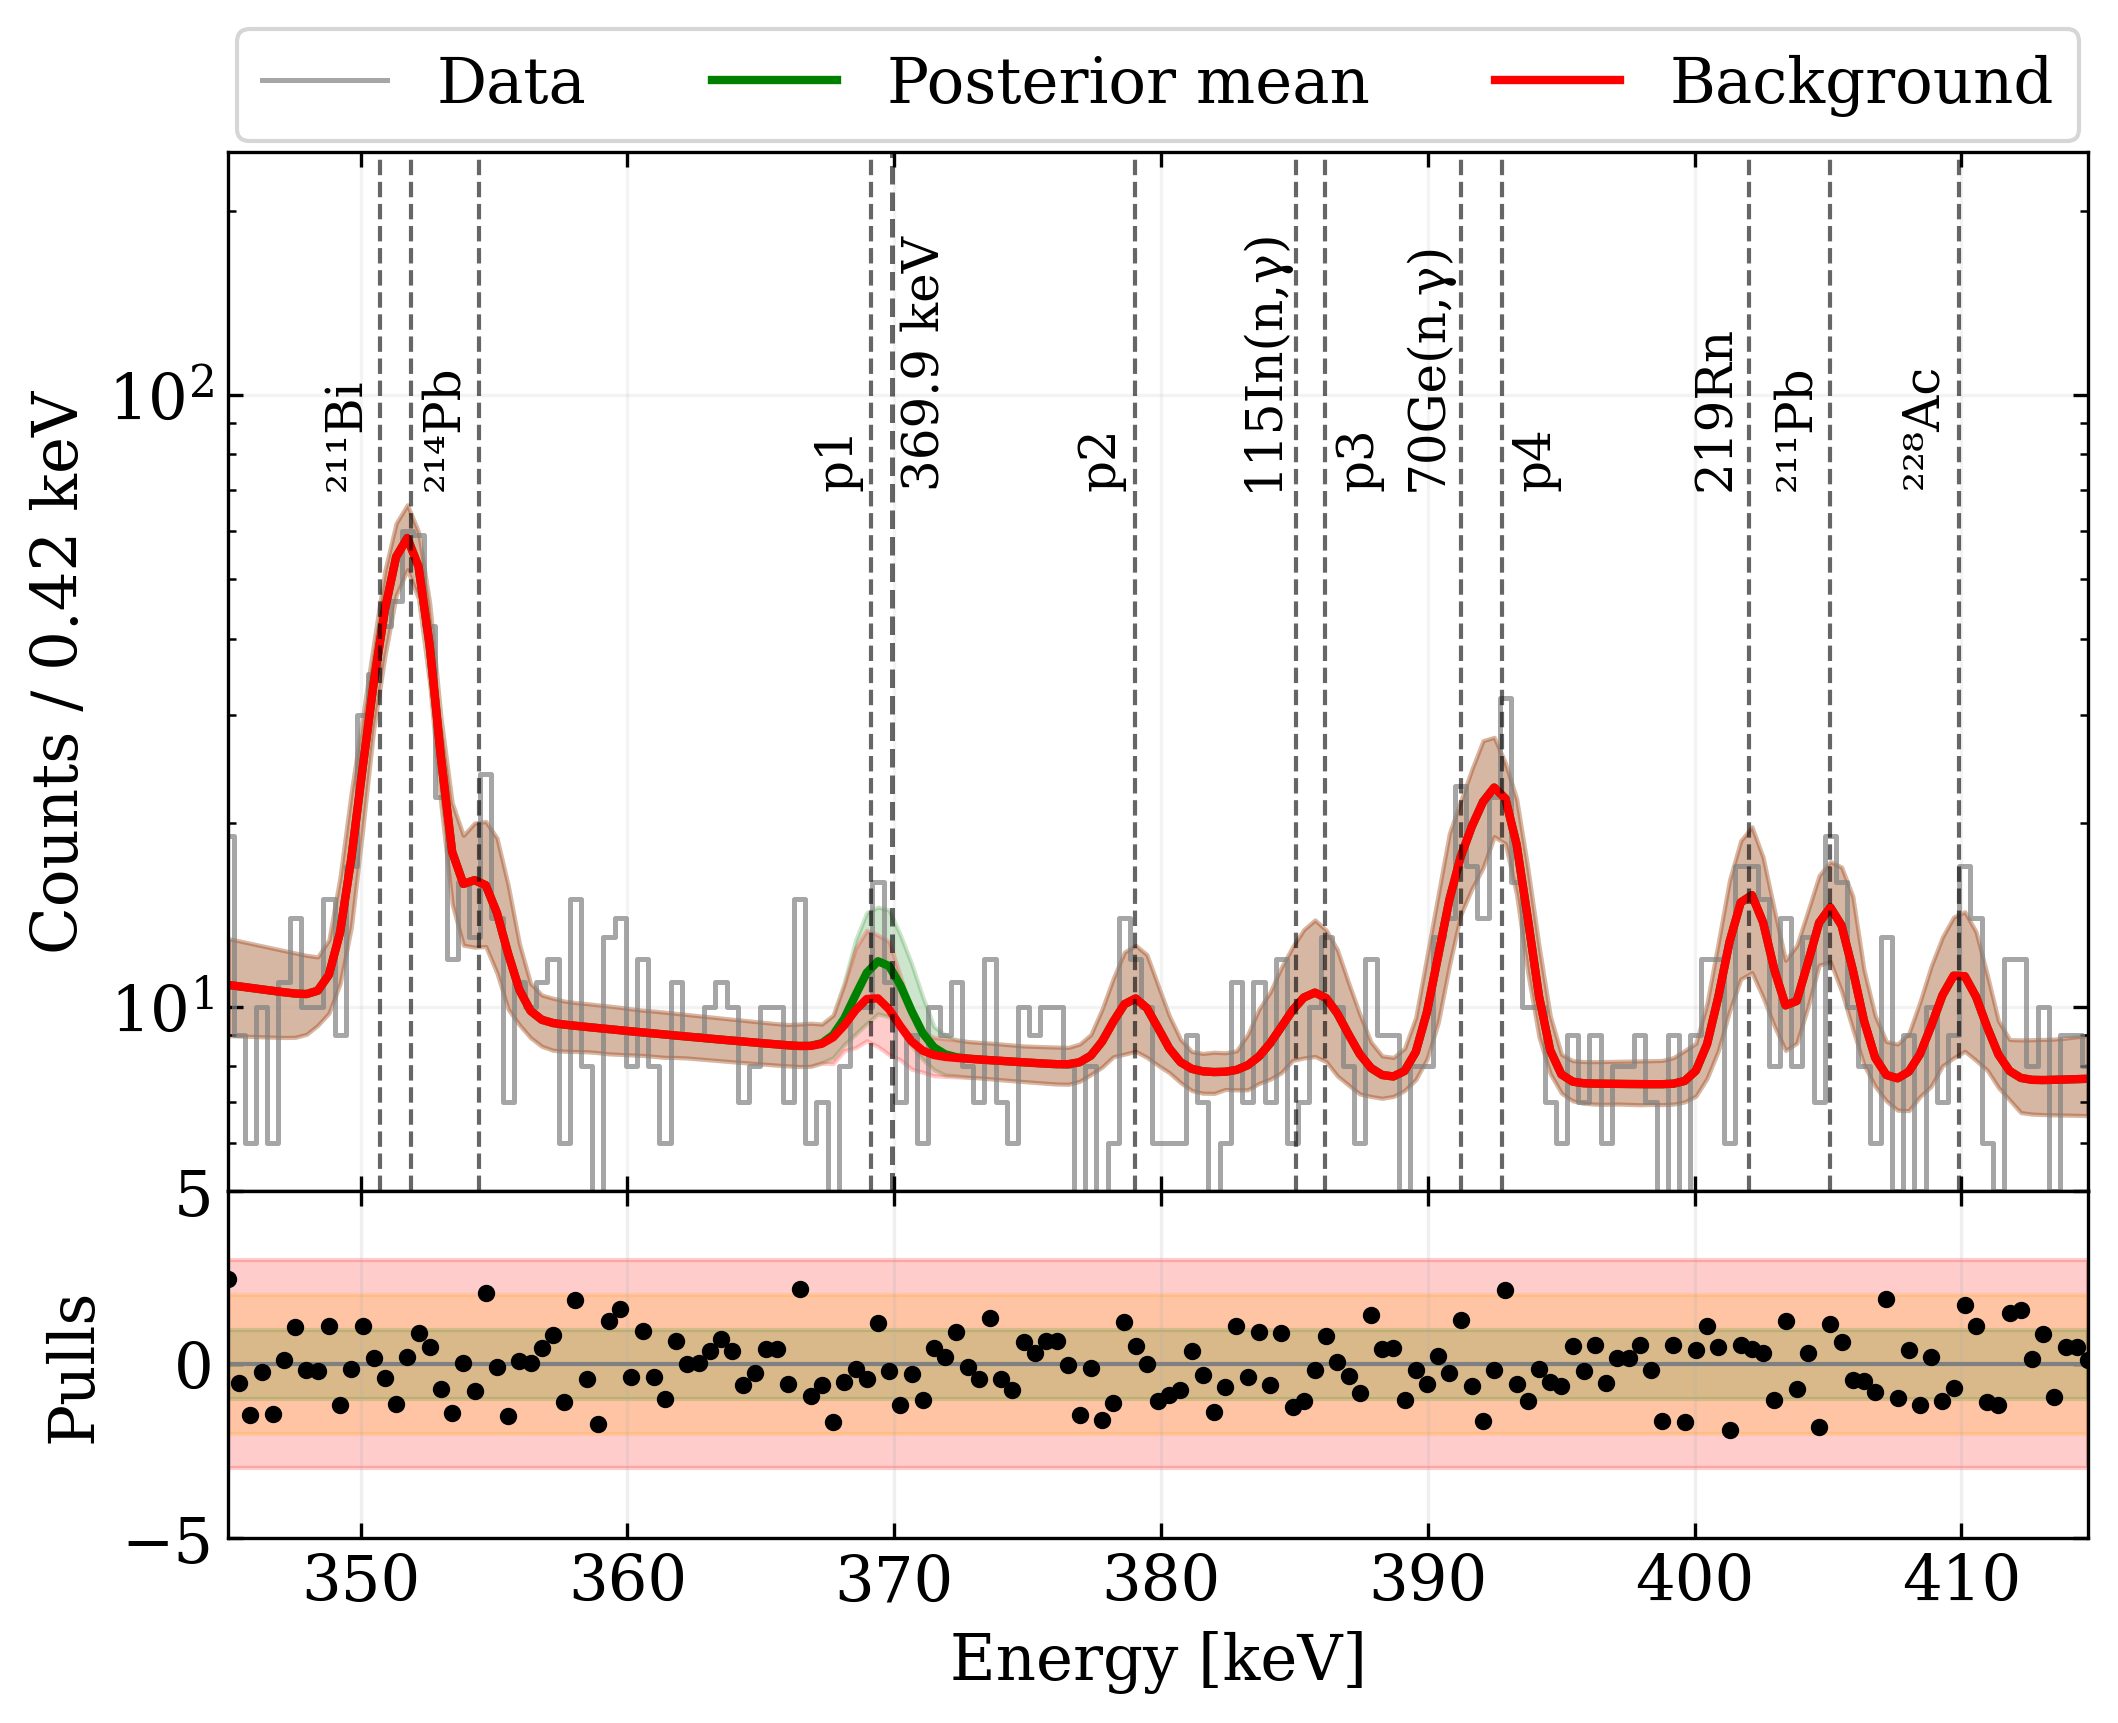

In [ ]:
# ============================================================
# BAYESIAN FIT BAND
# ============================================================

# lambda_total_samples:
# (N_posterior_samples, N_bins)

lambda_total_mean = np.mean(
    lambda_total_samples,
    axis=0
)

lambda_total_low = np.percentile(
    lambda_total_samples,
    5,
    axis=0
)

lambda_total_high = np.percentile(
    lambda_total_samples,
    95,
    axis=0
)


# background only

lambda_bkg_mean = np.mean(
    lambda_bkg_samples,
    axis=0
)

lambda_bkg_low = np.percentile(
    lambda_bkg_samples,
    5,
    axis=0
)

lambda_bkg_high = np.percentile(
    lambda_bkg_samples,
    95,
    axis=0
)



# ============================================================
# RESIDUALS
# ============================================================

residuals = (
    counts_roi - lambda_total_mean
) / np.sqrt(lambda_total_mean + 1e-9)



# ============================================================
# BIN CENTERS
# ============================================================

E_roi = 0.5*(edges_low + edges_high)



# ============================================================
# FIGURE
# ============================================================

fig, (ax1, ax2) = plt.subplots(
    2,
    1,
    sharex=True,
    gridspec_kw={"height_ratios": [3,1]},
    figsize=(8,6),
    dpi = 300
)



# ============================================================
# DATA
# ============================================================

ax1.step(
    E_roi,
    counts_roi,
    where="mid",
    color="grey",
    alpha=0.7,
    label="Data"
)



# ============================================================
# TOTAL BAYESIAN MODEL
# ============================================================

ax1.plot(
    E_roi,
    lambda_total_mean,
    #where="mid",
    color="green",
    lw=2,
    label="Posterior mean"
)


ax1.fill_between(
    E_roi,
    lambda_total_low,
    lambda_total_high,
    #step="mid",
    color="green",
    alpha=0.2,
    #label="68% credible interval"
)



# ============================================================
# BACKGROUND ONLY
# ============================================================

ax1.plot(
    E_roi,
    lambda_bkg_mean,
    #where="mid",
    color="red",
    lw=2,
    label="Background"
)


ax1.fill_between(
    E_roi,
    lambda_bkg_low,
    lambda_bkg_high,
    #step="mid",
    color="red",
    alpha=0.2
)


for name, peak in BACKGROUND_PEAKS.items():

    mu_samples = (
        trace.posterior[f"mu_{name}"]
        .values
        .flatten()
    )

    mu_fit = np.mean(mu_samples)

    ax1.axvline(
        mu_fit,
        color="black",
        linestyle="--",
        alpha=0.6,
        lw=1
    )

    x_text = mu_fit + 1.25 if name == "p3" or name == "p4" or name == "²¹⁴Pb" else mu_fit - 1.25

    ax1.text(
        x_text,
        70,
        f"{name}",
        rotation=90,
        verticalalignment="bottom",
        horizontalalignment="center",
        fontsize=12
    )



# ============================================================
# SIGNAL LINE
# ============================================================

ax1.axvline(
    SIGNAL["mu"],
    color="black",
    linestyle="--",
    alpha=0.6
)


ax1.text(
    SIGNAL["mu"]+1.25,
    70,
    f"{SIGNAL["mu"]:.1f} keV",
    rotation=90,
    verticalalignment="bottom",
    horizontalalignment="center",
    fontsize=12
)



# ============================================================
# AXES
# ============================================================

ax1.set_yscale("log")

ax1.set_xlim(
    E_roi.min(),
    E_roi.max()
)


ax1.set_ylim(
    5,
    250
    
)


ax1.set_ylabel(
    f"Counts / {edges_high[0]-edges_low[0]:.2f} keV"
)


ax1.grid(alpha=0.15)


ax1.legend(
    loc="lower center",
    bbox_to_anchor=(0.5,0.98),
    ncol=3
)



# ============================================================
# RESIDUALS
# ============================================================

ax2.scatter(
    E_roi,
    residuals,
    s=10,
    color="black",
    zorder = 5
)


ax2.axhspan(
    -3,
    3,
    color="red",
    alpha=0.2
)


ax2.axhspan(
    -2,
    2,
    color="orange",
    alpha=0.2
)


ax2.axhspan(
    -1,
    1,
    color="green",
    alpha=0.15
)


ax2.axhline(
    0,
    color="gray",
    lw=1,
    zorder=2
)



ax2.set_xlabel(
    "Energy [keV]"
)


ax2.set_ylabel(
    "Pulls"
)


ax2.set_ylim(
    -5,
    5
)


ax2.grid(alpha=0.2)



plt.subplots_adjust(hspace=0)

plt.show()

# half life

In [ ]:
# Dati campione
m_sample = 551.3        # massa ZrO2 in grammi
Mr_sample = 123.22      # massa molare ZrO2 [g/mol]
N_A = 6.022e23          # numero di Avogadro
eff_96Zr = 0.033387    # efficienza di rivelazione
i_a_96Zr = 0.0280     # abbondanza isotopica
t_live =  t_tot/(60*60*24*365)             # 90 giorni in anni


# Numero di nuclei 96Zr nel campione
N_nuclei = (m_sample * i_a_96Zr / Mr_sample) * N_A


In [ ]:
N_signal_90

np.float64(19.181282673739165)

In [ ]:

percentile = 90

T_half_limit = (np.log(2) * N_nuclei * eff_96Zr * t_live) / N_signal_90
print(f"T1/2 > {T_half_limit:.2e} yrs at {percentile}%")

T1/2 > 3.41e+19 yrs at 90%


In [ ]:
3.41e+19

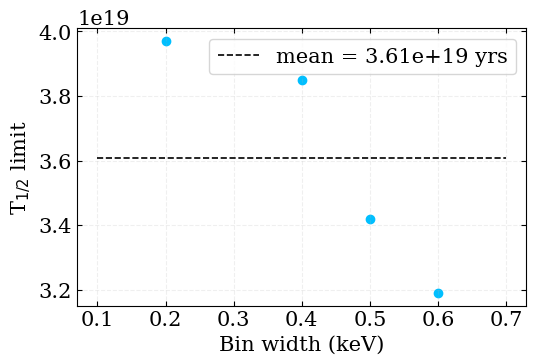

In [ ]:
limit = [3.97e19, 3.85e19, 3.42e19, 3.19e+19 ]# 0.8]

bin_width = [0.2, 0.4, 0.5, 0.6]

plt.scatter(bin_width, limit, color = 'deepskyblue')
plt.hlines(np.mean(limit), min(bin_width)-0.1, max(bin_width)+0.1, color = 'black', ls = '--', label = f"mean = {np.mean(limit):.2e} yrs")
plt.ylabel(fr"T$_{{1/2}}$ limit")
plt.xlabel('Bin width (keV)')
plt.legend()
plt.grid(alpha = 0.2, ls = '--')

# activities

In [ ]:
BACKGROUND_PEAKS = {
    "²¹¹Bi":{"E": 351.05, "N":0},
    "²¹⁴Pb": {"E": 351.92, "N": 0},
    "": {"E": 354.1, "N": 18},
    "70Ge(n,γ)": {"E": 391.3, "N" :0},
    "115In(n,γ)": {"E":385.1 , "N":0},
    "219Rn": {"E": 401.8, "N": 18},
    "²¹¹Pb": {"E": 404.85, "N": 18},
    "²²⁸Ac ": {"E": 409.462, "N": 3.55},
    "²¹¹Pb_2": {"E": 427.09, "N": 18},
    "⁴⁰K (DEP)" :{"E":438.9, "N":0},
    "p1" : {"E": 369, "N":0},

    "p2" : {"E": 379, "N":0},
    "p3" : {"E": 386, "N":0},
    "p4" : {"E": 393, "N":0},
    "p5" : {"E": 421, "N":0},
    "p6" : {"E": 433, "N":0}
}

In [ ]:
m_sample_kg

0.5513

In [ ]:
trace.posterior['A_²¹⁴Pb'].values.flatten()

array([166.49539552, 181.16257172, 211.51666593, ..., 164.46495791,
       152.66699192, 180.22142418], shape=(8000,))

In [ ]:
m_sample_kg= 0.5513
eff = np.array([
    0.0333])
br = np.array([
    0.3760])
samples = trace.posterior['A_²¹⁴Pb'].values.flatten()

activity = samples / (
        t_tot
        * m_sample_kg
        * eff
        * br
    )

print(
        f"{activity.mean()*1e3:.3f} ± "
        f"{activity.std()*1e3:.3f} mBq/kg"
    )

1.866 ± 0.397 mBq/kg
